# F4.1 y F4.7 — Recuperabilidad de **u** desde la imagen y correspondencia geométrica

**Procedencia.**
- Características de la penúltima capa extraídas en Kaggle desde el commit `9f3b7b0` (`results/f41_recuperabilidad/caracteristicas/`). Los `.npz` no se versionan: se leen de `f41_caracteristicas/` (ruta ignorada por git) y se verifica su sha256 contra `caracteristicas_manifest.csv`.
- F4.1: `recuperabilidad --val` (commit `a5d13c0`) y `recuperabilidad --prueba`, una sola consulta de prueba (commit `71f9277`).
- F4.7: `geometria` (solo `train`).
- Este notebook **no reajusta ningún modelo ni consulta prueba**. Las cifras salen de `resultados_val.json`, `resultados_prueba.json`, `results/f47_geometria/resultados.json` y `results/canonical_numbers.json`.
- Excepción: las matrices de distancia de `train` (figuras 3 y 4) se recalculan desde u y los `.npz`; antes se comprueba que su ρ de Spearman reproduce el de `resultados.json` con tolerancia 1e-12. No se repiten las permutaciones de Mantel.

**Regla de lectura** (`docs/plan_fase4.md`, tablas «qué se afirma / qué no»).
- R² alto: el componente es **linealmente** recuperable desde la penúltima capa del *backbone*; no que el clasificador lo use.
- En Perlin y Lorenz el *backbone* es el de ImageNet (idéntico en las 5 semillas del finalista congelado): la sonda mide lo que conserva la representación preentrenada, no lo que aprendió el clasificador.
- IC de ΔF1 que contiene 0: «compatible con ausencia de pérdida», no «equivalente». IC por encima de 0: se pierde información discriminativa en imagen + sonda, sin poder decir en qué etapa.
- ρ alto y Mantel significativo: se conserva la geometría de vecindades de **u** en `train`; no la dirección discriminativa.

In [1]:
import csv
import hashlib
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

T0 = time.time()
REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
for p in (REPO, REPO / 'src'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from viz import style
from src.fase4 import geometria as geo
from src.fase4 import recuperabilidad as rec

style.apply()
D41 = REPO / 'results' / 'f41_recuperabilidad'
D47 = REPO / 'results' / 'f47_geometria'
FIG41, FIG47 = D41 / 'figures', D47 / 'figures'
for d in (FIG41, FIG47):
    d.mkdir(parents=True, exist_ok=True)
NPZ_DIR = REPO / 'f41_caracteristicas'
MANIFEST = D41 / 'caracteristicas' / 'caracteristicas_manifest.csv'

VAL_DOC = json.loads((D41 / 'val' / 'resultados_val.json').read_text(encoding='utf-8'))
TEST_DOC = json.loads((D41 / 'prueba' / 'resultados_prueba.json').read_text(encoding='utf-8'))
F47_DOC = json.loads((D47 / 'resultados.json').read_text(encoding='utf-8'))
CANON_DOC = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))
CANON = CANON_DOC['numbers']
V, T, G = VAL_DOC['resultados'], TEST_DOC['resultados'], F47_DOC['resultados']

TECHS = ['gray_scott', 'perlin', 'lorenz']
LAB = style.TECH_LABEL
COL = style.TECH_COLOR
MARK = {'gray_scott': 's', 'perlin': 'o', 'lorenz': '^'}
PRIN = rec.PRINCIPAL
BB_LAB = {'efficientnet_b0_finetune_seed42': 'EfficientNet-B0 ajuste fino, semilla 42 (principal)',
          'efficientnet_b0_finetune_seed7': 'EfficientNet-B0 ajuste fino, semilla 7',
          'efficientnet_b0_finetune_seed123': 'EfficientNet-B0 ajuste fino, semilla 123',
          'efficientnet_b0_finetune_seed2024': 'EfficientNet-B0 ajuste fino, semilla 2024',
          'efficientnet_b0_finetune_seed99': 'EfficientNet-B0 ajuste fino, semilla 99',
          'efficientnet_b0_imagenet': 'EfficientNet-B0 ImageNet sin ajustar',
          'vit_b16_imagenet': 'ViT-B/16 ImageNet (= backbone del finalista congelado)'}
COMP = [f'u{i}' for i in range(5)]
FIGS = []


def pie(fig, text, y=-0.02, x=0.01):
    fig.text(x, y, text, ha='left', va='top', fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY, wrap=True)


def guardar(fig, carpeta, nombre, descripcion):
    path = style.save(fig, carpeta / nombre)
    FIGS.append({'archivo': path.relative_to(REPO).as_posix(), 'figura': descripcion})
    plt.show()
    return path


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def sha_lf(path):
    return hashlib.sha256(Path(path).read_bytes().replace(b'\r\n', b'\n')).hexdigest()

## 0. Procedencia y hashes

In [2]:
files = {'val/resultados_val.json': D41 / 'val' / 'resultados_val.json',
         'prueba/resultados_prueba.json': D41 / 'prueba' / 'resultados_prueba.json',
         'prueba/predicciones_prueba.csv': D41 / 'prueba' / 'predicciones_prueba.csv',
         'f47_geometria/resultados.json': D47 / 'resultados.json'}
rows = [('HEAD de --val (resultados_val.json:meta.git_commit)', VAL_DOC['meta']['git_commit']),
        ('HEAD de --prueba (resultados_prueba.json:meta.git_commit)', TEST_DOC['meta']['git_commit']),
        ('HEAD de geometria (resultados.json:meta.git_commit)', F47_DOC['meta']['git_commit']),
        ('Huella de los índices de A1 (idx_sha256)', TEST_DOC['meta']['idx_sha256']),
        ('Resoluciones (F4.1)', json.dumps(VAL_DOC['meta']['resoluciones'], ensure_ascii=False)),
        ('Resoluciones (F4.7)', json.dumps(F47_DOC['meta']['resoluciones'], ensure_ascii=False))]
for k, p in files.items():
    rel = p.relative_to(REPO).as_posix()
    rows.append((f'{k} — sha256 (LF; canonical_numbers.json:inputs)', sha_lf(p)))
    assert CANON_DOC['inputs'][rel] == sha_lf(p), rel
assert TEST_DOC['meta']['idx_sha256'] == '322edaaa5f1175bb4d4a16409d7f852fa7e67fa5daa8a504bb4976e67d0a7e37'
assert TEST_DOC['meta']['resoluciones'] == VAL_DOC['meta']['resoluciones']

with open(MANIFEST, newline='', encoding='utf-8') as f:
    MAN = {(r['tecnica'], r['backbone']): r for r in csv.DictReader(f)}
for (t, b), r in MAN.items():
    h = sha(NPZ_DIR / r['archivo'])
    assert h == r['sha256'], (t, b)
    rows.append((f'{r["archivo"]} — sha256 (= caracteristicas_manifest.csv)', h))
pd.set_option('display.max_colwidth', 120)
pd.DataFrame(rows, columns=['Campo', 'Valor'])

,Campo,Valor
0,HEAD de --val (resultados_val.json:meta.git_commit),e9959df13a842ef3d0107bf7d6cc2c2917e32a37
1,HEAD de --prueba (resultados_prueba.json:meta.git_commit),a5d13c0709f49738637a60f92845ff88a48057fb
2,HEAD de geometria (resultados.json:meta.git_commit),71f9277417a59b8c366e14a86522e4390b987f1b
3,Huella de los índices de A1 (idx_sha256),322edaaa5f1175bb4d4a16409d7f852fa7e67fa5daa8a504bb4976e67d0a7e37
4,Resoluciones (F4.1),"{""ridge_escalado"": ""standard_train"", ""alpha_desempate"": ""mayor"", ""alpha_crossfit"": ""seleccionado""}"
5,Resoluciones (F4.7),"{""mantel_lado"": ""mayor"", ""mantel_p"": ""k_mas_1_sobre_B_mas_1"", ""mantel_rng"": ""por_tecnica"", ""mantel_sensibilidad"": fa..."
6,val/resultados_val.json — sha256 (LF; canonical_numbers.json:inputs),028a55edc71ec7ad51b1f2dc4e43c963f12c7d29747c62a32fb271704458c597
7,prueba/resultados_prueba.json — sha256 (LF; canonical_numbers.json:inputs),4205b49d74361f1f397cdd4a39346979f1f6ce19227271b6e3a5bdb1a5f614df
8,prueba/predicciones_prueba.csv — sha256 (LF; canonical_numbers.json:inputs),c7c03fc044482df012dff2d486cbb4b95c40f86ab95576bc937903d244fc883f
9,f47_geometria/resultados.json — sha256 (LF; canonical_numbers.json:inputs),492a408ce441dfca998c10a3335f40bbcf6e7fc132fbe45c5c3ddbab05aaa687


## 1. R² por componente y técnica (F4.1)

Sonda Ridge multisalida sobre la penúltima capa, con alpha elegido por el R² medio de `val` y predicciones recortadas a [0, 1]. Los marcadores llenos son el *backbone* principal de cada técnica; en Gray-Scott, los huecos grises son la sensibilidad (las otras 4 semillas del finalista y EfficientNet-B0 ImageNet sin ajustar).

Fuentes: `resultados_val.json:resultados.tecnicas.<t>.<b>.r2_val` y `resultados_prueba.json:…r2_test` (claves `f41.val.*.r2.u<i>` y `f41.prueba.*.r2.u<i>`).

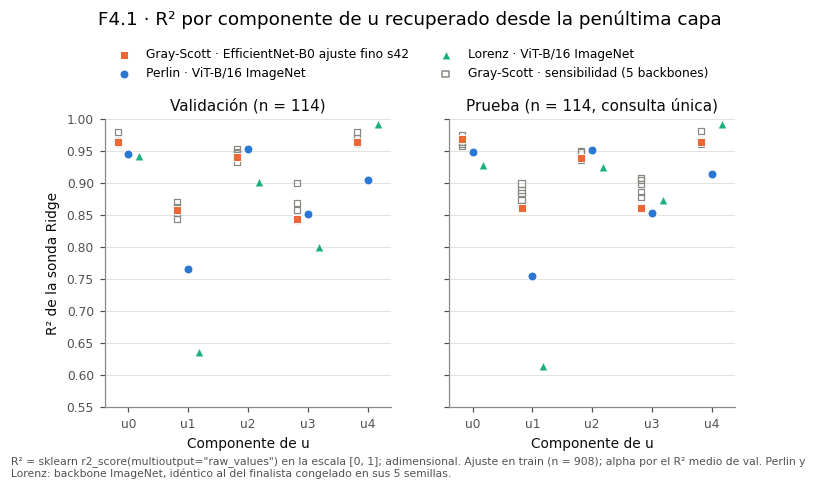

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f41_recuperabilidad/figures/f41_01_r2_por_componente.png')

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.4), sharey=True)
off = {'gray_scott': -0.18, 'perlin': 0.0, 'lorenz': 0.18}
for ax, (split, src, key, titulo) in zip(axes, [('val', V, 'r2_val', 'Validación (n = 114)'),
                                                ('prueba', T, 'r2_test', 'Prueba (n = 114, consulta única)')]):
    x = np.arange(5)
    for t in TECHS:
        for b, o in src['tecnicas'][t].items():
            if not isinstance(o, dict) or b == PRIN[t]:
                continue
            ax.scatter(x + off[t], o[key], s=16, facecolors='none', edgecolors=style.MUTED, marker=MARK[t],
                       linewidths=0.8, zorder=2)
        r2 = src['tecnicas'][t][PRIN[t]][key]
        for i in range(5):
            assert CANON[f'f41.{split}.{t}.{PRIN[t]}.r2.u{i}']['value']['val' if split == 'val' else 'test'] == r2[i]
        ax.scatter(x + off[t], r2, s=34, color=COL[t], marker=MARK[t], edgecolors='white', linewidths=0.6,
                   zorder=3, label=f'{LAB[t]} · {"EfficientNet-B0 ajuste fino s42" if t == "gray_scott" else "ViT-B/16 ImageNet"}')
    ax.set_xticks(x, COMP)
    ax.set_xlabel('Componente de u')
    ax.set_title(titulo)
    ax.set_ylim(0.55, 1.0)
    ax.grid(axis='y')
axes[0].set_ylabel('R² de la sonda Ridge')
axes[0].scatter([], [], s=16, facecolors='none', edgecolors=style.MUTED, marker='s', label='Gray-Scott · sensibilidad (5 backbones)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.10))
fig.suptitle('F4.1 · R² por componente de u recuperado desde la penúltima capa', y=1.17)
pie(fig, 'R² = sklearn r2_score(multioutput="raw_values") en la escala [0, 1]; adimensional. Ajuste en train (n = 908); '
         'alpha por el R² medio de val. Perlin y Lorenz: backbone ImageNet, idéntico al del finalista congelado en sus 5 semillas.')
guardar(fig, FIG41, 'f41_01_r2_por_componente', 'R² por componente de u y técnica, val y prueba (F4.1)')

In [4]:
tab = []
for t in TECHS:
    for b, o in V['tecnicas'][t].items():
        to = T['tecnicas'][t][b]
        tab.append({'técnica': LAB[t], 'backbone': BB_LAB[b], 'alpha': o['alpha'],
                    **{f'R² val {c}': round(v, 4) for c, v in zip(COMP, o['r2_val'])},
                    **{f'R² prueba {c}': round(v, 4) for c, v in zip(COMP, to['r2_test'])}})
pd.DataFrame(tab)

,técnica,backbone,alpha,R² val u0,R² val u1,R² val u2,R² val u3,R² val u4,R² prueba u0,R² prueba u1,R² prueba u2,R² prueba u3,R² prueba u4
0,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 42 (principal)",100.000000,0.9638,0.8579,0.9413,0.8440,0.9643,0.9684,0.8609,0.9391,0.8619,0.9651
1,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 7",316.227766,0.9642,0.8444,0.9327,0.8692,0.9666,0.9684,0.8997,0.9399,0.8867,0.9664
2,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 123",100.000000,0.9661,0.8543,0.9488,0.8452,0.9711,0.9653,0.8901,0.9386,0.8784,0.9634
3,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 2024",316.227766,0.9665,0.8705,0.9479,0.8588,0.9627,0.9610,0.8646,0.9487,0.9051,0.9651
4,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 99",316.227766,0.9633,0.8617,0.9529,0.8424,0.9625,0.9585,0.8736,0.9368,0.9086,0.9609
5,Gray-Scott,EfficientNet-B0 ImageNet sin ajustar,100.000000,0.9807,0.8622,0.9435,0.9009,0.9806,0.9748,0.8848,0.9497,0.8988,0.9818
6,Perlin,ViT-B/16 ImageNet (= backbone del finalista congelado),100.000000,0.9458,0.7656,0.9534,0.8526,0.9059,0.9492,0.7556,0.9515,0.8530,0.9142
7,Lorenz,ViT-B/16 ImageNet (= backbone del finalista congelado),10.000000,0.9422,0.6368,0.9014,0.8010,0.9928,0.9290,0.6143,0.9253,0.8734,0.9921


## 2. F1 de la LogReg sobre û frente a u, y ΔF1 con su IC (F4.1)

LogReg de §4.3 sobre û (u reconstruido por la sonda) y, de la misma forma, sobre u. ΔF1 = F1(u) − F1(û); IC percentil bilateral al 95 % sobre las réplicas de A1 (B = 10 000). Un ΔF1 negativo significa F1(û) > F1(u) en la muestra observada.

Fuentes: `resultados_prueba.json:resultados.tecnicas.<t>.<b>` (claves `f41.prueba.*.delta_f1*`, `f41.prueba.*.logreg_u_hat.f1_macro`, `f41.prueba.u.logreg.f1_macro`).

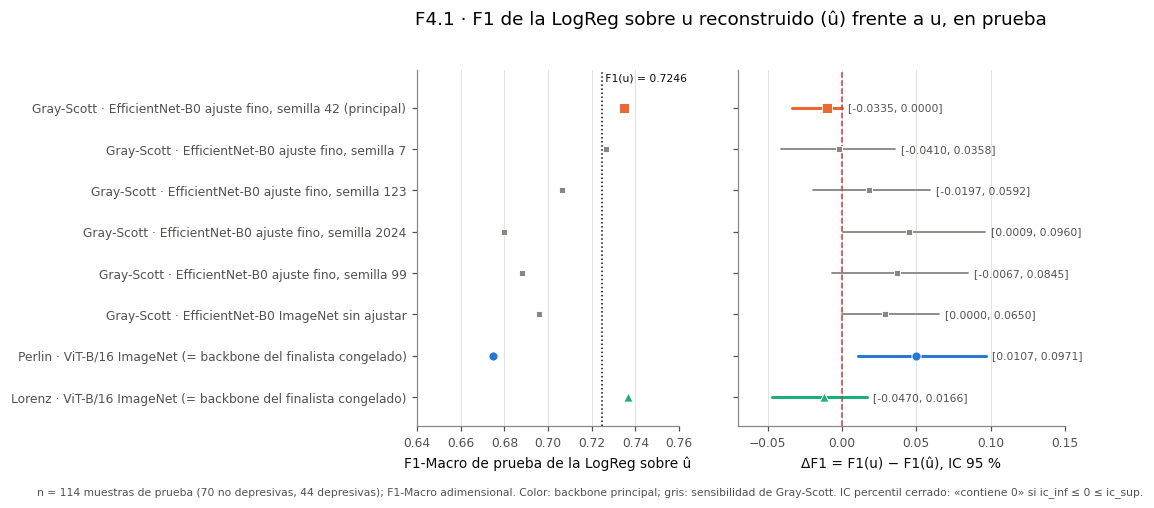

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f41_recuperabilidad/figures/f41_02_f1_u_hat_delta.png')

In [5]:
rows = []
for t in TECHS:
    rows.append((t, PRIN[t], True))
    rows += [(t, b, False) for b, o in T['tecnicas'][t].items() if isinstance(o, dict) and b != PRIN[t]]
f1_u = T['u']['f1_test']
assert f1_u == CANON['f41.prueba.u.logreg.f1_macro']['value']['test']

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 4.2), sharey=True, gridspec_kw={'width_ratios': [1, 1.25]})
ys = np.arange(len(rows))[::-1]
for y, (t, b, prin) in zip(ys, rows):
    o = T['tecnicas'][t][b]
    c = COL[t] if prin else style.MUTED
    a1.scatter([o['f1_u_hat']], [y], s=36 if prin else 20, color=c, marker=MARK[t], zorder=3,
               edgecolors='white', linewidths=0.6)
    lo, hi = o['ic']
    a2.plot([lo, hi], [y, y], color=c, lw=2.0 if prin else 1.2, solid_capstyle='round')
    a2.scatter([o['delta_f1_obs']], [y], s=36 if prin else 20, color=c, marker=MARK[t], zorder=3,
               edgecolors='white', linewidths=0.6)
    a2.text(hi + 0.004, y, f'[{lo:.4f}, {hi:.4f}]', va='center', fontsize=style.FONT_SIZES['annot'],
            color=style.INK_SECONDARY)
    assert CANON[f'f41.prueba.{t}.{b}.delta_f1_ic_inf']['value']['test'] == lo
    assert CANON[f'f41.prueba.{t}.{b}.delta_f1_ic_sup']['value']['test'] == hi
a1.axvline(f1_u, color=style.INK, ls=':', lw=1.0)
a1.text(f1_u, len(rows) - 0.4, f' F1(u) = {f1_u:.4f}', fontsize=style.FONT_SIZES['annot'], color=style.INK, va='bottom')
a1.set_xlabel('F1-Macro de prueba de la LogReg sobre û')
a1.set_yticks(ys, [f'{LAB[t]} · {BB_LAB[b]}' for t, b, _ in rows])
a1.set_xlim(0.64, 0.76)
a1.set_ylim(-0.7, len(rows) - 0.1)
a2.axvline(0, color=style.THRESHOLD_COLOR, ls='--', lw=1.0)
a2.set_xlabel('ΔF1 = F1(u) − F1(û), IC 95 %')
a2.set_xlim(-0.07, 0.15)
for a in (a1, a2):
    a.grid(axis='x')
fig.suptitle('F4.1 · F1 de la LogReg sobre u reconstruido (û) frente a u, en prueba', y=1.01)
pie(fig, 'n = 114 muestras de prueba (70 no depresivas, 44 depresivas); F1-Macro adimensional. Color: backbone principal; gris: '
         'sensibilidad de Gray-Scott. IC percentil cerrado: «contiene 0» si ic_inf ≤ 0 ≤ ic_sup.', x=-0.33)
guardar(fig, FIG41, 'f41_02_f1_u_hat_delta', 'F1 sobre û frente a u y ΔF1 con IC 95 %, prueba (F4.1)')

In [6]:
tab = [{'técnica': LAB[t], 'backbone': BB_LAB[b], 'F1 val û': round(V['tecnicas'][t][b]['logreg_u_hat']['f1_val'], 4),
        'F1 prueba û': round(T['tecnicas'][t][b]['f1_u_hat'], 4), 'F1 prueba u': round(T['tecnicas'][t][b]['f1_u'], 4),
        'ΔF1': round(T['tecnicas'][t][b]['delta_f1_obs'], 4),
        'IC 95 %': '[{:.4f}, {:.4f}]'.format(*T['tecnicas'][t][b]['ic']),
        'IC contiene 0': T['tecnicas'][t][b]['contiene_0']} for t, b, _ in rows]
print(f"F1 val de la LogReg sobre u: {V['u']['logreg_u']['f1_val']:.4f}; prueba: {f1_u:.4f}")
print({LAB[t]: T['tecnicas'][t]['condicion_2_F46'] for t in TECHS}, '← condición 2 de F4.6 (backbone principal)')
pd.DataFrame(tab)

F1 val de la LogReg sobre u: 0.7004; prueba: 0.7246
{'Gray-Scott': True, 'Perlin': False, 'Lorenz': True} ← condición 2 de F4.6 (backbone principal)


,técnica,backbone,F1 val û,F1 prueba û,F1 prueba u,ΔF1,IC 95 %,IC contiene 0
0,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 42 (principal)",0.6800,0.7348,0.7246,-0.0102,"[-0.0335, 0.0000]",True
1,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 7",0.7004,0.7267,0.7246,-0.0020,"[-0.0410, 0.0358]",True
2,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 123",0.7004,0.7063,0.7246,0.0184,"[-0.0197, 0.0592]",True
3,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 2024",0.6854,0.6796,0.7246,0.0451,"[0.0009, 0.0960]",False
4,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 99",0.6879,0.6879,0.7246,0.0367,"[-0.0067, 0.0845]",True
5,Gray-Scott,EfficientNet-B0 ImageNet sin ajustar,0.7165,0.6959,0.7246,0.0287,"[0.0000, 0.0650]",True
6,Perlin,ViT-B/16 ImageNet (= backbone del finalista congelado),0.6902,0.6747,0.7246,0.0499,"[0.0107, 0.0971]",False
7,Lorenz,ViT-B/16 ImageNet (= backbone del finalista congelado),0.6800,0.7367,0.7246,-0.0120,"[-0.0470, 0.0166]",True


## 3. Matrices de distancia de `train` (F4.7)

Distancia euclídea en u (escala [0, 1]) y distancia coseno en la penúltima capa, para las 908 muestras de `train`. Las filas y columnas siguen el mismo orden en los cuatro paneles: el de las hojas de un agrupamiento jerárquico (enlace promedio) de u, para que la estructura de u sea visible.

Comprobación previa: el ρ de Spearman de los pares i < j se recalcula con `geometria.spearman_dist` y debe coincidir con `results/f47_geometria/resultados.json` (tolerancia 1e-12). No se repiten las 9,999 permutaciones.

In [7]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

index = rec.load_index()
U_tr = rec.load_u(index, ('train',))['train'][0]
Du = geo.dist_u(U_tr)
DX, RHO_CHK = {}, []
for t in TECHS:
    X, digest = rec.load_features(str(NPZ_DIR), str(MANIFEST), t, PRIN[t], index, ('train',))
    assert digest == G['principal'][t]['npz_sha256']
    DX[t] = geo.dist_features(X['train'])
    rho = geo.spearman_dist(Du, DX[t])
    ref = G['principal'][t]['rho_spearman']
    assert abs(rho - ref) <= 1e-12, (t, rho, ref)
    assert CANON[f'f47.{t}.rho_spearman']['value']['train'] == ref
    RHO_CHK.append({'técnica': LAB[t], 'ρ recalculado': rho, 'ρ en resultados.json': ref, '|dif|': abs(rho - ref)})
(D47 / 'figures' / 'reproduccion_rho.json').write_text(json.dumps(RHO_CHK, indent=1, ensure_ascii=False) + '\n', encoding='utf-8')
order = leaves_list(linkage(squareform(Du, checks=False), method='average'))
pd.DataFrame(RHO_CHK)

,técnica,ρ recalculado,ρ en resultados.json,|dif|
0,Gray-Scott,0.801934,0.801934,0.0
1,Perlin,0.522104,0.522104,0.0
2,Lorenz,0.319093,0.319093,0.0


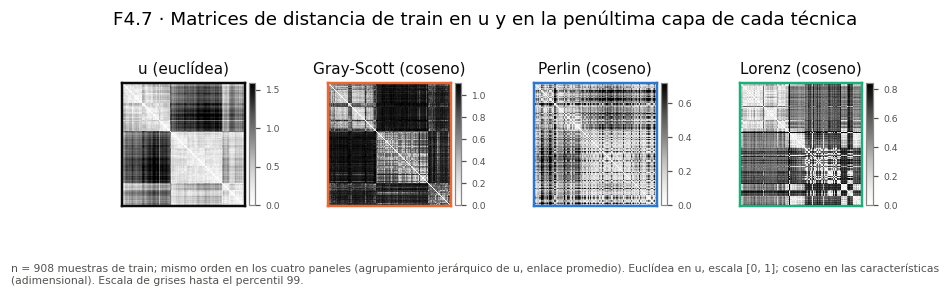

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f47_geometria/figures/f47_01_matrices_distancia.png')

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(8.8, 2.5))
fig.subplots_adjust(wspace=0.55)
panels = [('u (euclídea)', Du, style.INK)] + [(f'{LAB[t]} (coseno)', DX[t], COL[t]) for t in TECHS]
for ax, (tit, D, c) in zip(axes, panels):
    M = D[np.ix_(order, order)]
    im = ax.imshow(M, cmap='Greys', vmin=0, vmax=np.quantile(M, 0.99))
    ax.set_title(tit, color=style.INK)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True); s.set_edgecolor(c); s.set_linewidth(1.6)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cb.ax.tick_params(labelsize=6)
fig.suptitle('F4.7 · Matrices de distancia de train en u y en la penúltima capa de cada técnica', y=0.98)
pie(fig, 'n = 908 muestras de train; mismo orden en los cuatro paneles (agrupamiento jerárquico de u, enlace promedio). '
         'Euclídea en u, escala [0, 1]; coseno en las características (adimensional). Escala de grises hasta el percentil 99.', y=0.06)
guardar(fig, FIG47, 'f47_01_matrices_distancia', 'Matrices de distancia de train en u y en las características (F4.7)')

## 4. Distancias por par y ρ de Mantel (F4.7)

Cada panel resume los 411,778 pares i < j de `train`. ρ de Spearman observado, valor p de Mantel ((k + 1)/(B + 1), cola superior, B = 9,999) y Holm con m = 3.

Fuentes: `results/f47_geometria/resultados.json:resultados.principal.<t>` (claves `f47.*`).

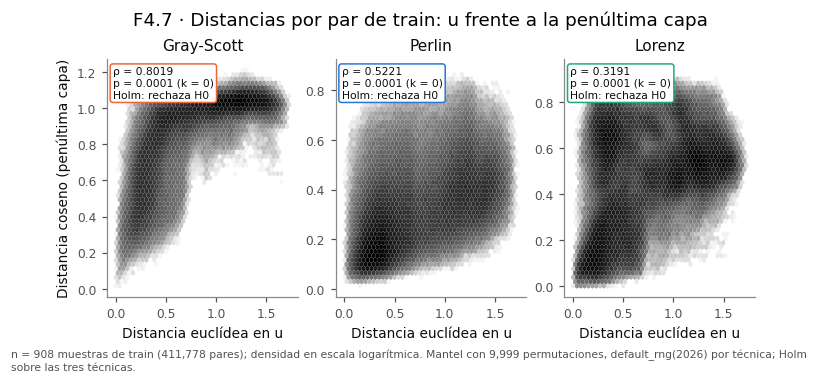

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f47_geometria/figures/f47_02_pares_mantel.png')

In [9]:
iu = np.triu_indices(Du.shape[0], k=1)
du = Du[iu]
fig, axes = plt.subplots(1, 3, figsize=(7.6, 2.8), sharex=True)
for ax, t in zip(axes, TECHS):
    g = G['principal'][t]
    ax.hexbin(du, DX[t][iu], gridsize=45, cmap='Greys', mincnt=1, bins='log', linewidths=0)
    ax.set_title(LAB[t], color=style.INK)
    ax.set_xlabel('Distancia euclídea en u')
    holm = 'rechaza H0' if g['holm']['reject'] else 'no rechaza H0'
    ax.text(0.03, 0.97, f"ρ = {g['rho_spearman']:.4f}\np = {g['p']:.4f} (k = {g['k']})\nHolm: {holm}",
            transform=ax.transAxes, va='top', fontsize=style.FONT_SIZES['annot'], color=style.INK,
            bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=COL[t], lw=1.0))
axes[0].set_ylabel('Distancia coseno (penúltima capa)')
fig.suptitle('F4.7 · Distancias por par de train: u frente a la penúltima capa', y=1.04)
pie(fig, 'n = 908 muestras de train (411,778 pares); densidad en escala logarítmica. Mantel con 9,999 permutaciones, '
         'default_rng(2026) por técnica; Holm sobre las tres técnicas.', y=-0.06)
guardar(fig, FIG47, 'f47_02_pares_mantel', 'Distancias por par de train y ρ de Mantel por técnica (F4.7)')

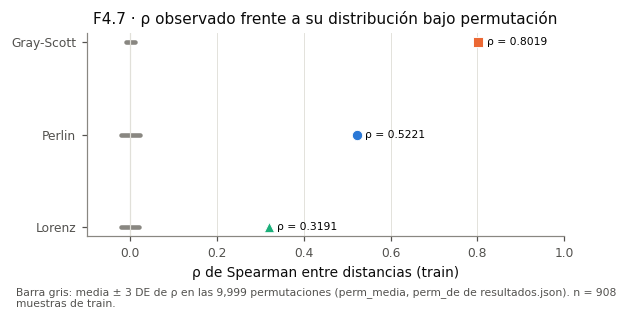

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f47_geometria/figures/f47_03_rho_vs_permutacion.png')

In [10]:
fig, ax = plt.subplots(figsize=(5.6, 2.4))
for y, t in zip([2, 1, 0], TECHS):
    g = G['principal'][t]
    m, s = g['perm_media'], g['perm_de']
    ax.plot([m - 3 * s, m + 3 * s], [y, y], color=style.MUTED, lw=3, solid_capstyle='round')
    ax.scatter([g['rho_spearman']], [y], s=46, color=COL[t], marker=MARK[t], zorder=3, edgecolors='white', linewidths=0.6)
    ax.text(g['rho_spearman'] + 0.02, y, f"ρ = {g['rho_spearman']:.4f}", va='center', fontsize=style.FONT_SIZES['annot'])
ax.set_yticks([2, 1, 0], [LAB[t] for t in TECHS])
ax.set_xlabel('ρ de Spearman entre distancias (train)')
ax.set_xlim(-0.1, 1.0)
ax.axvline(0, color=style.GRID, lw=0.8)
ax.grid(axis='x')
ax.set_title('F4.7 · ρ observado frente a su distribución bajo permutación')
pie(fig, 'Barra gris: media ± 3 DE de ρ en las 9,999 permutaciones (perm_media, perm_de de resultados.json). '
         'n = 908 muestras de train.', y=-0.08)
guardar(fig, FIG47, 'f47_03_rho_vs_permutacion', 'ρ de Mantel observado frente a la distribución bajo permutación (F4.7)')

In [11]:
pd.DataFrame([{'técnica': LAB[t], 'backbone': BB_LAB[PRIN[t]], 'n': g['n'], 'ρ': round(g['rho_spearman'], 4),
               'k': g['k'], 'p': g['p'], 'rango Holm': g['holm']['rank'], 'α Holm': round(g['holm']['alpha_h'], 4),
               'rechaza': g['holm']['reject'], 'media perm.': round(g['perm_media'], 5), 'DE perm.': round(g['perm_de'], 5)}
              for t, g in ((t, G['principal'][t]) for t in TECHS)])

,técnica,backbone,n,ρ,k,p,rango Holm,α Holm,rechaza,media perm.,DE perm.
0,Gray-Scott,"EfficientNet-B0 ajuste fino, semilla 42 (principal)",908,0.8019,0,0.0001,1,0.0167,True,-0.00001,0.00335
1,Perlin,ViT-B/16 ImageNet (= backbone del finalista congelado),908,0.5221,0,0.0001,1,0.0167,True,-0.00000,0.00735
2,Lorenz,ViT-B/16 ImageNet (= backbone del finalista congelado),908,0.3191,0,0.0001,1,0.0167,True,0.00001,0.00703


## Figuras generadas

In [12]:
TABLA = pd.DataFrame(FIGS)
(FIG41 / 'figuras.json').write_text(json.dumps({'figuras': FIGS, 'segundos_kernel': round(time.time() - T0, 1)},
                                               indent=1, ensure_ascii=False) + '\n', encoding='utf-8')
print(f'{len(FIGS)} figuras; tiempo del kernel: {time.time() - T0:.1f} s')
TABLA

5 figuras; tiempo del kernel: 9.1 s


,archivo,figura
0,results/f41_recuperabilidad/figures/f41_01_r2_por_componente.png,"R² por componente de u y técnica, val y prueba (F4.1)"
1,results/f41_recuperabilidad/figures/f41_02_f1_u_hat_delta.png,"F1 sobre û frente a u y ΔF1 con IC 95 %, prueba (F4.1)"
2,results/f47_geometria/figures/f47_01_matrices_distancia.png,Matrices de distancia de train en u y en las características (F4.7)
3,results/f47_geometria/figures/f47_02_pares_mantel.png,Distancias por par de train y ρ de Mantel por técnica (F4.7)
4,results/f47_geometria/figures/f47_03_rho_vs_permutacion.png,ρ de Mantel observado frente a la distribución bajo permutación (F4.7)
